# Week 7 · Shear hands-on: Shear bias estimation from image simulations

In this notebook we measure the **shear bias** of two shape-measurement methods on image simulations, and find out where the bias comes from.

The simulations are LSST-like r-band images at 10-year depth. Each tile covers 1 deg², with a 0.73″ Moffat PSF and 0.2″ pixels. The galaxies come from the Flagship-2 cosmological simulation, with morphologies learnt from Hubble Space Telescope observations of the COSMOS field, down to r = 28. The images were made with [MultiBand_ImSim](https://github.com/KiDS-WL/MultiBand_ImSim).

**The shear bias model.** For a constant input shear $g^{\rm true}$, the mean estimated shear of a galaxy sample is

$$\langle \hat g_i \rangle = (1 + m_i)\, g_i^{\rm true} + c_i ,$$

where $m$ is the *multiplicative* and $c$ the *additive* bias. For its ten-year analysis, the LSST Dark Energy Science Collaboration requires $m$ to be known to better than $3\times10^{-3}$ (DESC Science Requirements Document, Mandelbaum et al. 2018, [arXiv:1809.01669](https://arxiv.org/abs/1809.01669)).

**How the simulations are set up for measuring it:**
- Every setup is simulated three times, with $(g_1, g_2) = (-0.03, 0)$, $(0, 0)$ and $(+0.03, 0)$, using the **same noise and galaxies**. Then
  we fit a straight line, $\langle\hat g_1\rangle = (1 + m_1)\, g_1^{\rm true} + c_1$, through the three runs: its slope gives $m_1$ and its intercept $c_1$. Part of the noise cancels between the runs.
  Because the three shears are equally spaced, the fitted slope is simply $(\langle\hat g_1\rangle_{+} - \langle\hat g_1\rangle_{-})/0.06$, and the $g = 0$ run constrains only the intercept.
- Every image also has a twin with each galaxy **rotated by 90°**. Averaging the two cancels the galaxies' intrinsic shapes, which is *shape-noise cancellation*.
- Only $g_1$ is varied, so we can measure $m_1$, $c_1$ and $c_2$, but not $m_2$. In practice both are measured; they usually have similar values, so one often quotes $m = (m_1 + m_2)/2$.

**The four setups**, with increasing realism:

| setup | galaxies | stars |
|---|---|---|
| `grid_pos` | on an 18″ grid, with no overlap and no clustering. Only 20 < r < 25, to keep the image small. | – |
| `random_pos` | at random positions, so they overlap (*blending*) but are not clustered | – |
| `true_pos` | at the mock's positions, so they overlap and are clustered following the Flagship-2 large-scale structure | – |
| `true_pos_stars` | as `true_pos` | random positions |

**The two shear measurements:**
- **KSB** (`galsim.hsm`): measures a moment-based shear estimate for each galaxy, on objects detected by SExtractor. The estimate is not calibrated.
- **metadetection** (Sheldon et al. 2020, 2023): detects and measures objects in the image *and* in versions artificially sheared by ±0.01 (`1p`, `1m`, `2p`, `2m`). From those it measures the shear response $R$ of the whole pipeline, detection and selection included, and corrects for it: $\hat g = \langle g\rangle_{\rm noshear} / R$.

**How to use it.** Run on the Rubin Science Platform (<https://data.lsst.cloud>) with the **LSST** kernel, on a **Medium** server or larger: the notebook needs about 2 GB of memory. Run the cells in order, because later sections use the functions defined earlier. Running every cell takes about 5 minutes. The **Questions** after each section are to think about; Section 6, *Going further*, has exercises that need some code.

**AI-use note.** This notebook was developed with the help of an AI assistant, Claude Opus 5.5 (Anthropic; model ID `claude-opus-5-5`), used through Claude Code. It drafted and revised the text and the code, ran the analyses, and checked the numbers quoted in the text against the outputs.

**Words you will meet.** *Shear* ($g_1$, $g_2$): the coherent stretch that lensing imprints on galaxy shapes; $g_1$ stretches along x and y, $g_2$ along the diagonals. *Shape noise*: the scatter of galaxies' intrinsic shapes, about 0.25 per component, far larger than the shear. *Multiplicative* and *additive bias* ($m$, $c$): how a measured mean shear departs from the true one. *PSF*: the point-spread function, the blur of telescope and atmosphere that every image is convolved with. *Blending*: light from neighbouring objects overlapping in the image. *KSB* (Kaiser, Squires & Broadhurst 1995): a classic shape measurement from weighted second moments, corrected for the PSF. *Metacalibration* and *metadetection*: measure the shear response of the whole pipeline by shearing the image itself by a small known amount and running everything again. *Response* ($R$): how much the measured shape changes per unit of applied shear; $\hat g = \langle g\rangle / R$. *Resolution factor* ($R_2$): 0 for an object as small as a point source, 1 for one much larger than the PSF. *Selection* and *detection bias*: biases from cuts and from which objects are detected, when those depend on the shear itself. *Jackknife*: errors from the scatter of the result when each patch of sky is left out in turn. *runTag*: the name of one simulation run, e.g. `p030p000` for $g_1 = +0.03$, $g_2 = 0$.

## 0. Setup and data

The data (2.7 GB) are in `/home/liss/data/week7/imsim`, a directory every RSP user can read, so you don't need to copy them. If you run somewhere else, point `DATA_DIR` at your copy (or set the `PHYS367_DATA` environment variable).

The folder holds one subfolder per setup (`<setup>/`). Each contains the image cutouts (`cutouts.fits`, Section 1), the catalogue of all simulated galaxies (`input_galaxies.fits`, Section 2), and one subfolder per shear (`<runTag>/`) with two KSB and two metadetect catalogues (`rot0`, `rot90`).

Each method has its own column names. The loader below gives both the same names:

| name | KSB | metadetect |
|---|---|---|
| `g1`, `g2` | `e1/e2_shear_HSM_LSST_r` | `wmom_g_1/2` |
| `w` | `weight_HSM_LSST_r` | 1 |
| `valid` | finite \|g\| < 1, w > 0 | `wmom_flags == 0` |
| `snr` | `FLUX_AUTO / FLUXERR_AUTO` | `wmom_s2n` |
| `mag_obs` | `MAG_AUTO` | from `wmom_band_flux`, zero point 30 |
| `size_obs` | `resolution_factor_HSM_LSST_r` (0: unresolved … 1: much larger than the PSF) | `wmom_T_ratio` (object size² / PSF size², both measured on the PSF-convolved image: 1 for a point source) |
| `x`, `y` | `X_WORLD`, `Y_WORLD` (deg) | same |
| `shear_type` | – | `noshear`, `1p`, `1m`, `2p`, `2m` |

The input truth comes from matching each detection to the input catalogue; it is −999 or NaN when there is no match:

| name | meaning |
|---|---|
| `id_input` | input object id |
| `star` | 1 for a matched star |
| `z_true` | true redshift |
| `mag_true` | true r magnitude |
| `size_true` | true half-light radius, in arcsec |

In [1]:
import os
import functools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = os.environ.get('PHYS367_DATA', '/home/liss/data/week7/imsim')

SETUPS = ['grid_pos', 'random_pos', 'true_pos', 'true_pos_stars']
METHODS = ['ksb', 'metadetect']
SHEARS = {'m030p000': -0.03, 'p000p000': 0.0, 'p030p000': +0.03}   # runTag: input g1
ROTS = [0, 90]
STEP = 0.01      # metacal shear step used by metadetect
ZP = 30.         # magnitude zero point of the images
PSF_FWHM = 0.73  # arcsec, the round Moffat PSF (beta = 2.22) of the images
PSF_HLR = 0.53   # arcsec, its half-light radius: galsim.Moffat(beta=2.22, fwhm=0.73).half_light_radius
NJK = 10         # NJK x NJK spatial patches for jackknife errors

FILES = {'ksb': 'tile0.0_0.0_rot{rot}_combined_hsm.fits',
         'metadetect': 'tile0.0_0.0_bandLSST_r_rot{rot}_combined_metadetect.fits'}
COLORS = {'ksb': 'tab:orange', 'metadetect': 'tab:blue'}
## the fiducial shear sample: valid measurements with S/N > 10, and for metadetect T_ratio > 0.5
FIDUCIAL_CUT = {'ksb': lambda d: d.snr > 10,
                'metadetect': lambda d: (d.snr > 10) & (d.size_obs > 0.5)}
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})

## check the data are there
_files = ([os.path.join(s, t, FILES[m].format(rot=r)) for s in SETUPS for t in SHEARS for m in METHODS for r in ROTS]
          + [os.path.join(s, f) for s in SETUPS for f in ['cutouts.fits', 'input_galaxies.fits']])
_missing = [f for f in _files if not os.path.isfile(os.path.join(DATA_DIR, f))]
if _missing:
    raise FileNotFoundError(f'{len(_missing)} of {len(_files)} files not found in {DATA_DIR}, e.g. {_missing[0]}. '
                            'Point DATA_DIR (or PHYS367_DATA) at the folder with the data.')
print(f'all {len(_files)} files found in {DATA_DIR}')

all 56 files found in /home/liss/data/week7/imsim


In [2]:
def _read_fits(path):
    # FITS table -> dict of native-endian numpy arrays
    try:
        import fitsio
        data = fitsio.read(path)
    except ImportError:
        from astropy.table import Table
        data = Table.read(path).as_array()
    out = {}
    for name in data.dtype.names:
        col = np.asarray(data[name])
        if col.dtype.kind in 'SU':
            col = np.char.strip(col.astype(str))
        else:
            col = col.astype(col.dtype.newbyteorder('='))
        out[name] = col
    return out


@functools.lru_cache(maxsize=12)
def load(setup, method, tag, rot):
    # one catalogue, with the common column names of the table above
    d = _read_fits(os.path.join(DATA_DIR, setup, tag, FILES[method].format(rot=rot)))
    with np.errstate(divide='ignore', invalid='ignore'):
        if method == 'ksb':
            g1, g2, w = d['e1_shear_HSM_LSST_r'], d['e2_shear_HSM_LSST_r'], d['weight_HSM_LSST_r']
            cat = dict(g1=g1, g2=g2, w=w,
                       valid=np.isfinite(g1) & (np.abs(g1) < 1) & (np.abs(g2) < 1) & (w > 0),
                       snr=np.where(d['FLUXERR_AUTO'] > 0, d['FLUX_AUTO'] / d['FLUXERR_AUTO'], 0.),
                       mag_obs=d['MAG_AUTO'],
                       size_obs=d['resolution_factor_HSM_LSST_r'])
        else:
            flux = d['wmom_band_flux']
            cat = dict(shear_type=pd.Categorical(d['shear_type']),
                       g1=d['wmom_g_1'], g2=d['wmom_g_2'], w=np.ones(len(flux), 'f4'),
                       valid=d['wmom_flags'] == 0,
                       snr=d['wmom_s2n'],
                       mag_obs=np.where(flux > 0, ZP - 2.5 * np.log10(flux), np.nan).astype('f4'),
                       size_obs=d['wmom_T_ratio'])
    cat.update(x=d['X_WORLD'], y=d['Y_WORLD'], id_input=d['id_input'], star=d['perfect_flag_star'])
    for new, old in [('z_true', 'redshift_input'), ('mag_true', 'LSST_r_input'), ('size_true', 'Re_input')]:
        cat[new] = np.where(d['id_input'] >= 0, d[old], np.nan).astype('f4')
    return pd.DataFrame(cat)


cat = load('true_pos', 'metadetect', 'p000p000', 0)
print(f'{len(cat)} rows'); cat.head()

1484839 rows


,shear_type,g1,g2,w,valid,snr,mag_obs,size_obs,x,y,id_input,star,z_true,mag_true,size_true
0,noshear,0.035106,-0.244364,1.0,True,16.544565,26.206324,0.767607,152.897582,0.100574,87395759,0,2.734117,25.543312,0.068586
1,noshear,0.061816,-0.019967,1.0,True,15.025313,26.310904,1.146834,152.899904,0.100739,236247727,0,0.905551,25.825516,0.104589
2,noshear,-0.017519,-0.085219,1.0,True,31.646231,25.502157,1.173189,152.899483,0.101629,212111836,0,0.671726,24.872398,0.295957
3,noshear,-0.261861,0.062165,1.0,True,11.409129,26.609831,1.336398,152.897226,0.101709,201440821,0,0.890159,26.045296,0.111727
4,noshear,0.170009,0.116301,1.0,True,18.324116,26.095406,1.363432,152.898725,0.101934,194209355,0,0.671705,25.616264,0.197296


## 1. A look at the images

Before measuring anything, let us look at what was simulated. `cutouts.fits` in each setup's folder holds a 2′ × 2′ patch (600 × 600 pixels) of the images, centred on the tile centre:

| HDU | content |
|---|---|
| `G0_ROT0`, `G0_ROT90` | input shear $g = 0$, and the same scene with every galaxy rotated by 90° |
| `GP_ROT0`, `GM_ROT0` | $g_1 = +0.03$ and $-0.03$, with exactly the same noise |
| `PSF` | the PSF |
| `INPUT` | the simulated galaxies and stars inside the patch: true position, magnitude, size |

The three setups with mock positions (`random_pos`, `true_pos`, `true_pos_stars`) are cut at the same place on the sky; `random_pos` has the same galaxies, but moved to random positions.

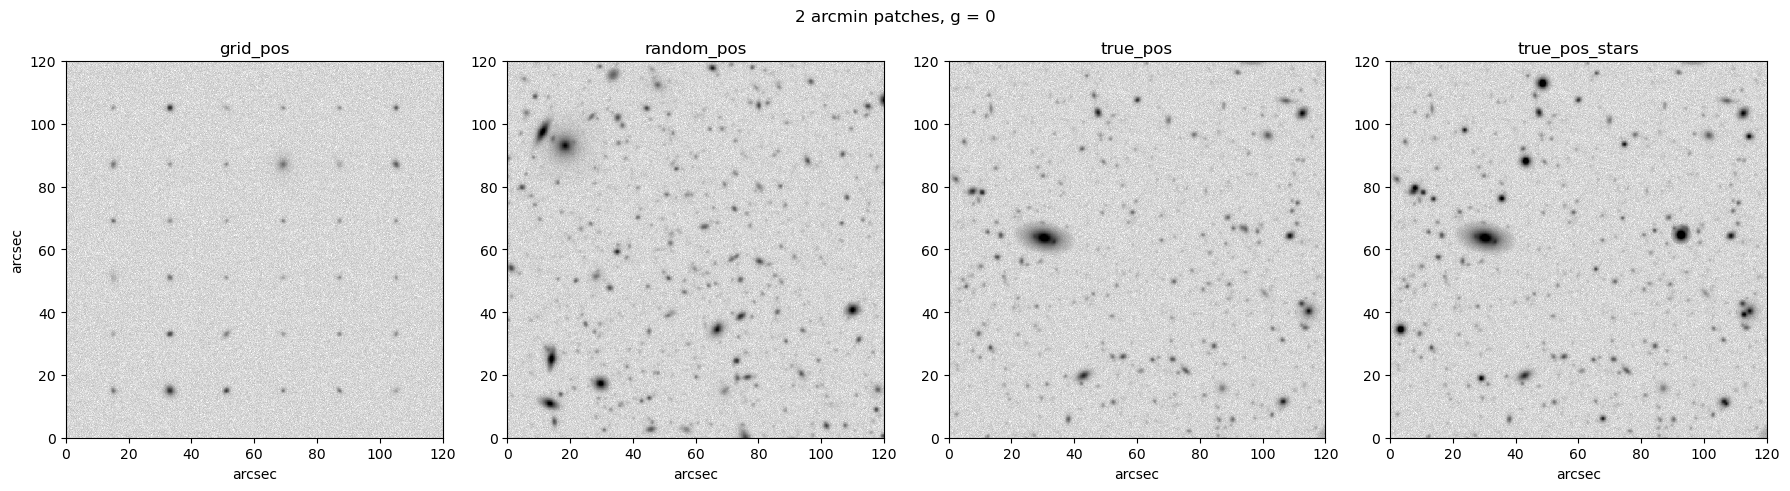

In [3]:
from astropy.wcs import WCS
from astropy.io import fits
from astropy.visualization import AsinhStretch, ImageNormalize


@functools.lru_cache(maxsize=None)
def load_cutouts(setup):
    with fits.open(os.path.join(DATA_DIR, setup, 'cutouts.fits')) as h:
        out = {hdu.name: hdu.data.astype(float) for hdu in h[1:] if hdu.is_image}
        out['WCS'] = WCS(h['G0_ROT0'].header)
        out['INPUT'] = pd.DataFrame(np.asarray(h['INPUT'].data).astype(h['INPUT'].data.dtype.newbyteorder('=')))
    return out


NORM = ImageNormalize(vmin=-1., vmax=60., stretch=AsinhStretch(0.02))    # noise rms ~ 0.3 per pixel
EXTENT = [0, 600 * 0.2, 0, 600 * 0.2]                                    # arcsec


def show(ax, img, title='', norm=NORM, cmap='gray_r'):
    ax.imshow(img, origin='lower', norm=norm, cmap=cmap, extent=EXTENT, interpolation='none')
    ax.set_title(title); ax.set_xlabel('arcsec'); ax.grid(False)


fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, setup in zip(axes, SETUPS):
    show(ax, load_cutouts(setup)['G0_ROT0'], setup)
axes[0].set_ylabel('arcsec'); plt.suptitle('2 arcmin patches, g = 0'); plt.tight_layout(); plt.show()

### What the detections see

We zoom into the `true_pos_stars` patch and overlay the truth and the two detection lists:
- **dots:** the simulated objects, coloured by true magnitude; stars are marked with stars.
- **circles:** SExtractor detections, which KSB measures.
- **squares:** metadetect detections in the `noshear` image.

Look for blends, where two or more true galaxies give a single detection, and for faint galaxies that no one detects.

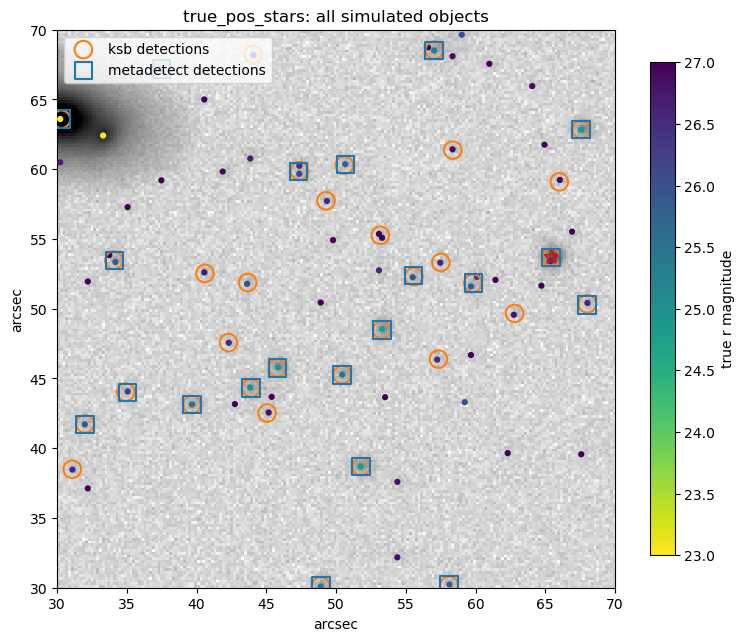

In [4]:
def to_pix(wcs, ra, dec):
    x, y = wcs.all_world2pix(np.asarray(ra), np.asarray(dec), 0)
    return x * 0.2, y * 0.2                                      # arcsec within the patch


setup, zoom = 'true_pos_stars', (30, 70)                         # arcsec window inside the patch
cut = load_cutouts(setup)
wcs, inp = cut['WCS'], cut['INPUT']

fig, ax = plt.subplots(figsize=(9, 8))
show(ax, cut['G0_ROT0'], f'{setup}: all simulated objects')
gal = inp[inp.star == 0]
x, y = to_pix(wcs, gal.ra, gal.dec)
sc = ax.scatter(x, y, c=gal.mag_true, s=12, cmap='viridis_r', vmin=23, vmax=27, zorder=3)
st = inp[inp.star == 1]
ax.scatter(*to_pix(wcs, st.ra, st.dec), marker='*', s=120, facecolor='none', edgecolor='r', zorder=3)
for method, marker, color in [('ksb', 'o', 'tab:orange'), ('metadetect', 's', 'tab:blue')]:
    d = load(setup, method, 'p000p000', 0)
    if method == 'metadetect':
        d = d[d.shear_type == 'noshear']
    x, y = to_pix(wcs, d.x, d.y)
    ok = (x > zoom[0]) & (x < zoom[1]) & (y > zoom[0]) & (y < zoom[1])
    ax.scatter(x[ok], y[ok], marker=marker, s=160, facecolor='none', edgecolor=color, lw=1.5,
               label=f'{method} detections', zorder=4)
ax.set_xlim(zoom); ax.set_ylim(zoom); ax.set_ylabel('arcsec')
plt.colorbar(sc, ax=ax, label='true r magnitude', shrink=0.8); ax.legend(loc='upper left'); plt.show()

### The PSF, and the rotated twin

All galaxies are convolved with the same PSF. Compare the size of the PSF with the faint galaxies above: most of them are barely larger than the PSF.

In the grid setup it's easy to see what the 90° rotation does: each galaxy is turned in place. Averaged over the pair, the intrinsic shapes cancel, while the shear stays the same in both.

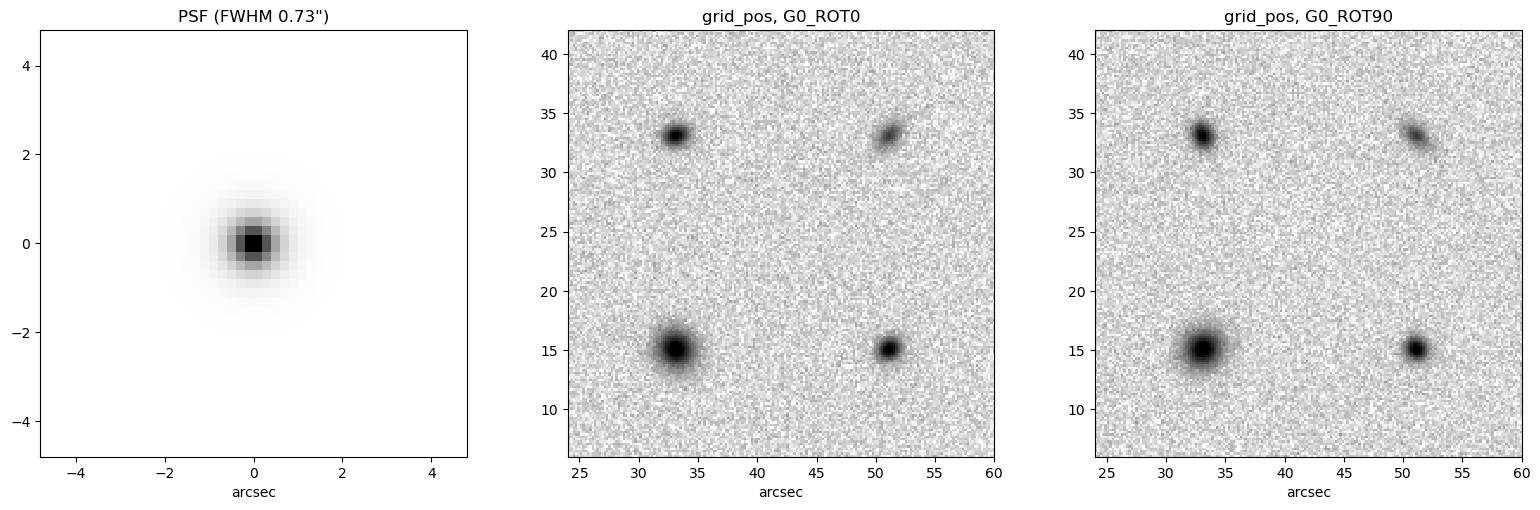

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
psf = load_cutouts('true_pos')['PSF']
n = psf.shape[0]
axes[0].imshow(psf, origin='lower', cmap='gray_r', extent=[-n * 0.1, n * 0.1, -n * 0.1, n * 0.1])
axes[0].set_title('PSF (FWHM 0.73")'); axes[0].set_xlabel('arcsec'); axes[0].grid(False)
grid = load_cutouts('grid_pos')
for ax, name in zip(axes[1:], ['G0_ROT0', 'G0_ROT90']):
    show(ax, grid[name], f'grid_pos, {name}', norm=ImageNormalize(vmin=-0.5, vmax=15., stretch=AsinhStretch(0.05)))
    ax.set_xlim(24, 60); ax.set_ylim(6, 42)                      # 2 x 2 grid cells
plt.tight_layout(); plt.show()

### What a shear of 3% looks like

The images with $g_1 = +0.03$ and $g_1 = -0.03$ share **exactly the same noise**. So their difference shows the shear alone. The galaxy positions are sheared too, about the tile centre at the middle of the patch. That's why the residuals grow towards the edges, and why their pattern stretches along x for $g_1 > 0$ and along y for $g_1 < 0$.

By eye, the two sheared images look identical. A 3% shear is far below the intrinsic ellipticities of galaxies, which are typically about 25%. That's why shear is measured statistically, by averaging many galaxies.

grid_pos: noise per pixel of one image 0.317, of the difference 0.000
true_pos: noise per pixel of one image 0.351, of the difference 0.036


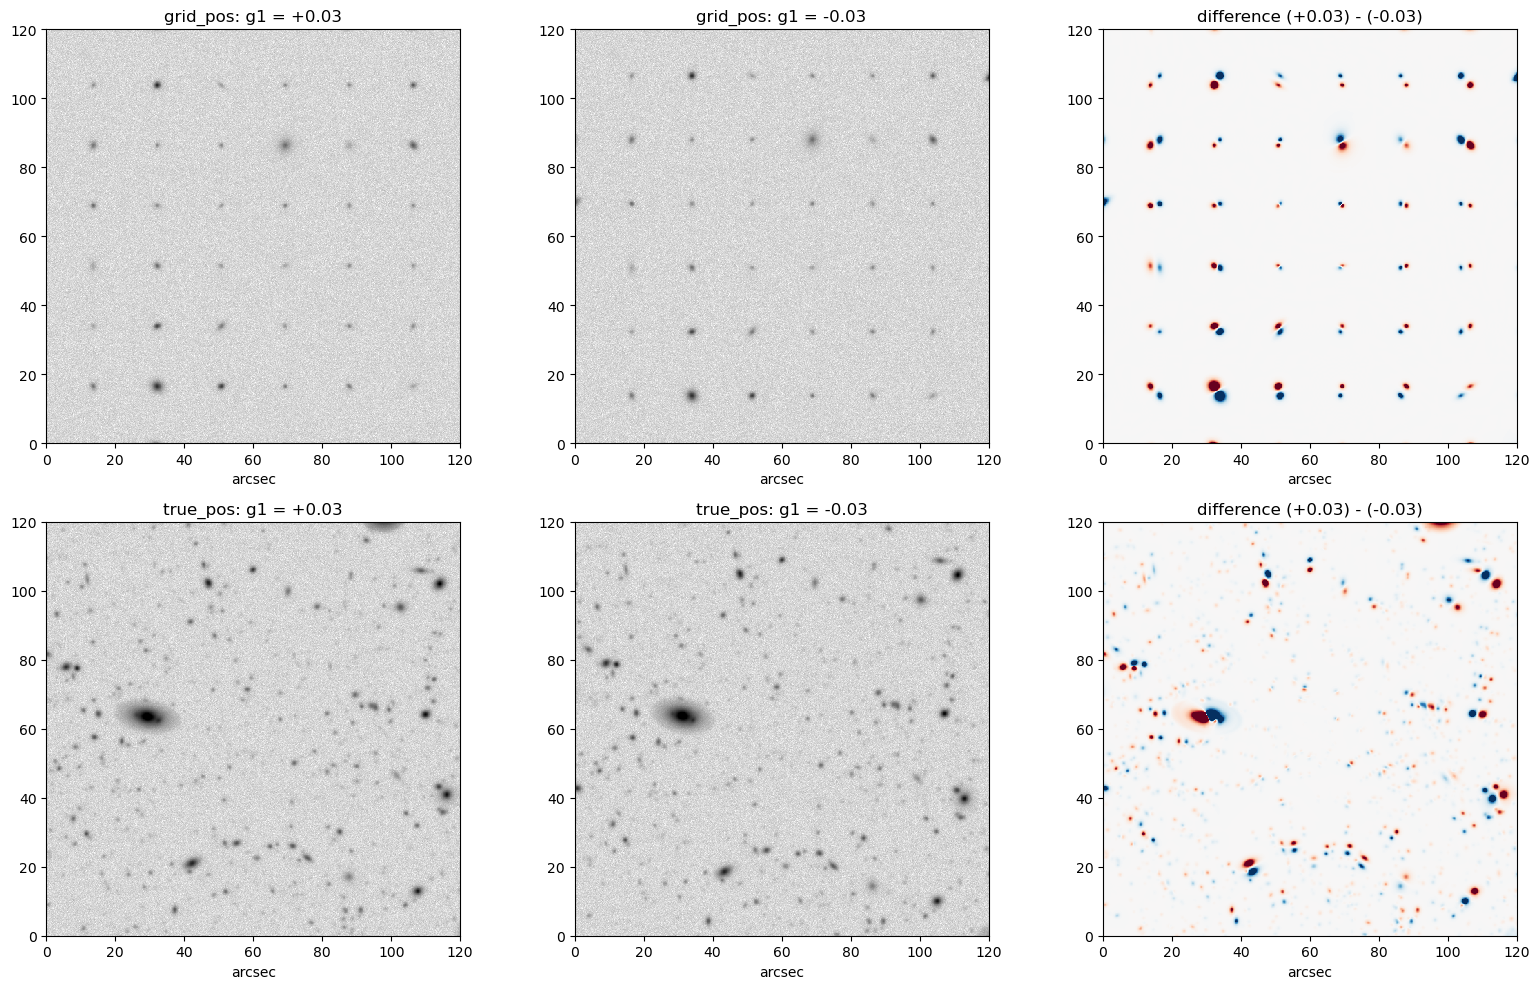

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for row, setup in zip(axes, ['grid_pos', 'true_pos']):
    c = load_cutouts(setup)
    show(row[0], c['GP_ROT0'], f'{setup}: g1 = +0.03')
    show(row[1], c['GM_ROT0'], f'{setup}: g1 = -0.03')
    diff = c['GP_ROT0'] - c['GM_ROT0']
    lim = np.nanpercentile(np.abs(diff), 99.5)
    row[2].imshow(diff, origin='lower', cmap='RdBu_r', vmin=-lim, vmax=lim, extent=EXTENT, interpolation='none')
    row[2].set_title('difference (+0.03) - (-0.03)'); row[2].set_xlabel('arcsec'); row[2].grid(False)
    noise = lambda a: 1.4826 * np.median(np.abs(a - np.median(a)))     # robust: ignores the objects
    print(f'{setup}: noise per pixel of one image {noise(c["GP_ROT0"]):.3f}, of the difference {noise(diff):.3f}')
plt.tight_layout(); plt.show()

### Questions

1. Why is there no noise in the difference image?
2. What does that buy us when measuring the shear bias, compared with simulating every shear with new noise?

## 2. Galaxy properties: magnitude and size

`input_galaxies.fits` in each setup's folder lists **every simulated galaxy** (`id_input`, `mag_true`, `size_true` = half-light radius in arcsec, `z_true`, `axis_ratio_true`). The shear catalogues only contain the galaxies that were **detected**, so comparing the two shows which galaxies make it into a shear sample.

In [7]:
@functools.lru_cache(maxsize=None)
def load_input(setup):
    d = _read_fits(os.path.join(DATA_DIR, setup, 'input_galaxies.fits'))
    return pd.DataFrame(d)


def detected(setup, method, cut=None):
    # input galaxies detected (and passing cut) in the g = 0, rot0 catalogue
    d = load(setup, method, 'p000p000', 0)
    m = (d.id_input >= 0) & (d.star == 0) & d.valid
    if method == 'metadetect':
        m &= d.shear_type == 'noshear'
    if cut is not None:
        m &= cut(d)
    return load_input(setup).id_input.isin(d.id_input[m]).values


inp = load_input('true_pos')
print(f'true_pos: {len(inp)} simulated galaxies in 1 deg2, i.e. {len(inp) / 3600:.0f} per arcmin2')
for method in METHODS:
    det, sel = detected('true_pos', method), detected('true_pos', method, FIDUCIAL_CUT[method])
    print(f'   {method:>10s}: {det.sum():7d} detected ({det.sum() / 3600:.0f}/arcmin2), '
          f'{sel.sum():7d} in the shear sample ({sel.sum() / 3600:.0f}/arcmin2)')

true_pos: 896297 simulated galaxies in 1 deg2, i.e. 249 per arcmin2
          ksb:  317281 detected (88/arcmin2),  205306 in the shear sample (57/arcmin2)
   metadetect:  293948 detected (82/arcmin2),  276770 in the shear sample (77/arcmin2)


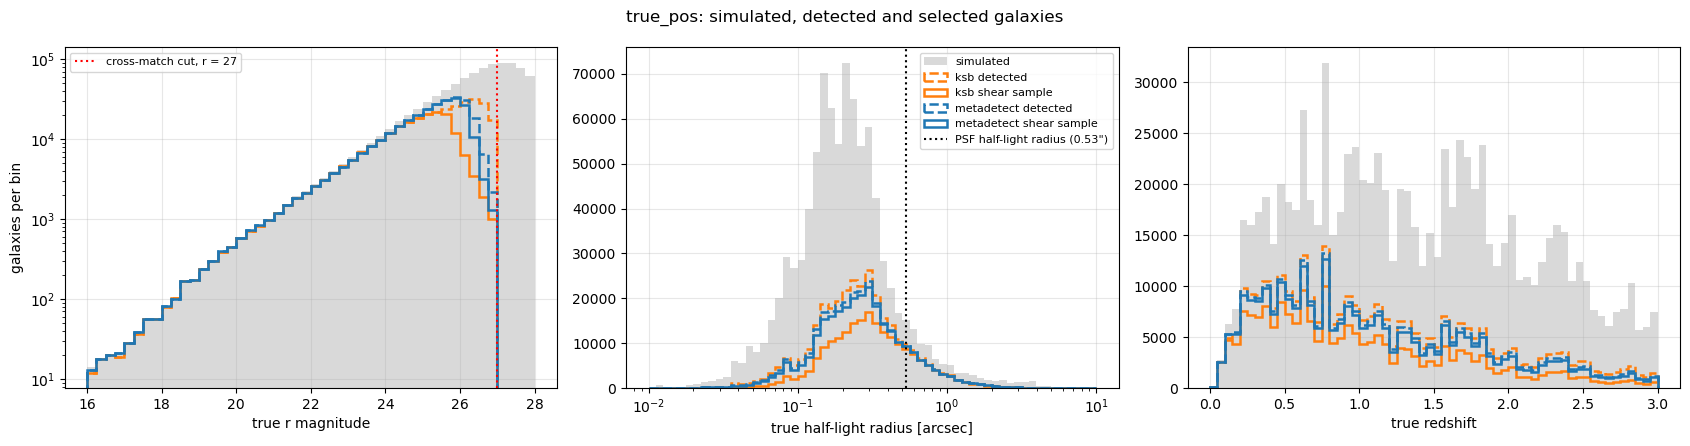

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
inp = load_input('true_pos')
for ax, col, bins, label in [(axes[0], 'mag_true', np.arange(16, 28.25, 0.25), 'true r magnitude'),
                             (axes[1], 'size_true', np.logspace(-2, 1, 61), 'true half-light radius [arcsec]'),
                             (axes[2], 'z_true', np.arange(0, 3.05, 0.05), 'true redshift')]:
    ax.hist(inp[col], bins=bins, histtype='stepfilled', color='0.85', label='simulated')
    for method in METHODS:
        for cut, ls, what in [(None, '--', 'detected'), (FIDUCIAL_CUT[method], '-', 'shear sample')]:
            ax.hist(inp[col][detected('true_pos', method, cut)], bins=bins, histtype='step', lw=1.8, ls=ls,
                    color=COLORS[method], label=f'{method} {what}')
    ax.set_xlabel(label)
axes[1].set_xscale('log'); axes[1].axvline(PSF_HLR, c='k', ls=':', label=f'PSF half-light radius ({PSF_HLR}")')
lim = axes[0].axvline(27, c='r', ls=':', label='cross-match cut, r = 27')
axes[0].set_yscale('log'); axes[0].set_ylabel('galaxies per bin'); axes[1].legend(fontsize=8)
axes[0].legend(handles=[lim], loc='upper left', fontsize=8)
plt.suptitle('true_pos: simulated, detected and selected galaxies'); plt.tight_layout(); plt.show()

### Completeness

The fraction of simulated galaxies that end up in the shear sample, as a function of true magnitude and size (for r < 27, the cross-match cut), for every setup:

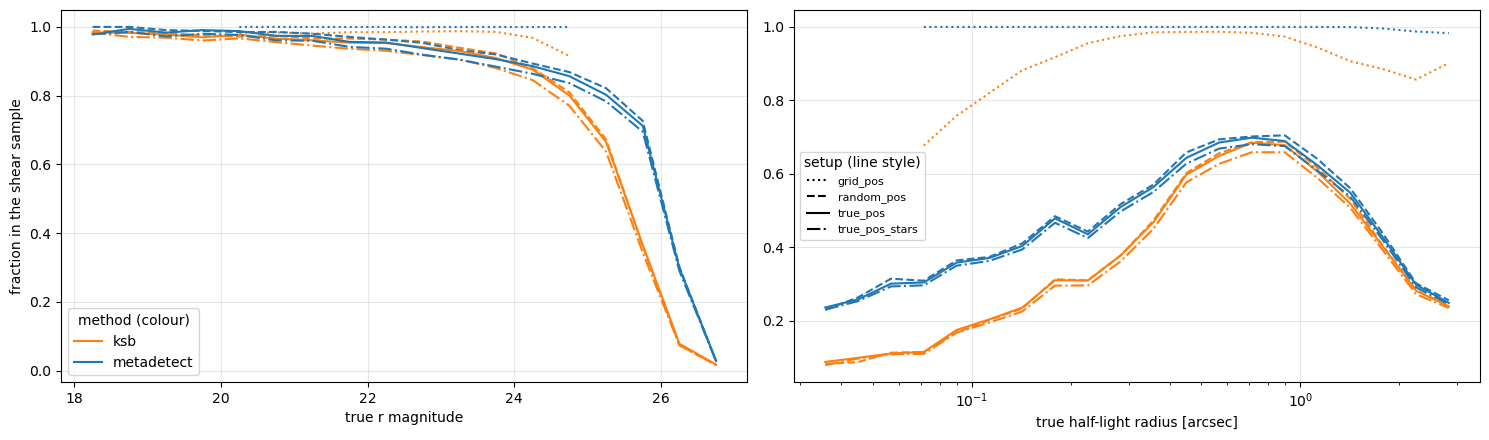

In [9]:
from matplotlib.lines import Line2D

LINESTYLES = dict(zip(SETUPS, [':', '--', '-', '-.']))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
mbins, sbins = np.arange(18, 27.01, 0.5), np.logspace(-1.5, 0.5, 21)
for setup in SETUPS:
    inp = load_input(setup)
    bright = (inp.mag_true < 27).values
    inp = inp[bright]
    for method in METHODS:
        sel = detected(setup, method, FIDUCIAL_CUT[method])[bright]
        for ax, col, bins in [(axes[0], 'mag_true', mbins), (axes[1], 'size_true', sbins)]:
            n_all, _ = np.histogram(inp[col], bins)
            n_sel, _ = np.histogram(inp[col][sel], bins)
            frac = np.where(n_all >= 50, n_sel / np.maximum(n_all, 1), np.nan)    # skip bins with fewer than 50 galaxies
            ax.plot(0.5 * (bins[1:] + bins[:-1]), frac, ls=LINESTYLES[setup], color=COLORS[method])
axes[0].set_xlabel('true r magnitude'); axes[1].set_xlabel('true half-light radius [arcsec]'); axes[1].set_xscale('log')
axes[0].set_ylabel('fraction in the shear sample')
axes[0].legend(handles=[Line2D([], [], color=COLORS[m], label=m) for m in METHODS], loc='lower left', title='method (colour)')
axes[1].legend(handles=[Line2D([], [], color='k', ls=LINESTYLES[s], label=s) for s in SETUPS], loc='center left',
               title='setup (line style)', fontsize=8)
plt.tight_layout(); plt.show()

### Measured against true

The measured quantities show what blending does: a detection that is really two galaxies is **brighter** than either of them, and usually **larger**. We compare `true_pos` with `grid_pos`, where nothing overlaps.

Each method's `size_obs` has its own scale, so for the sizes we take the grid as the reference: the black lines are the grid's median and 84th percentile of `size_obs` at each true size. Both setups are restricted to the grid's range, 20 < r < 25, so the comparison is like for like. Without blending, `true_pos` would have about as many galaxies above the dashed line as the grid itself.

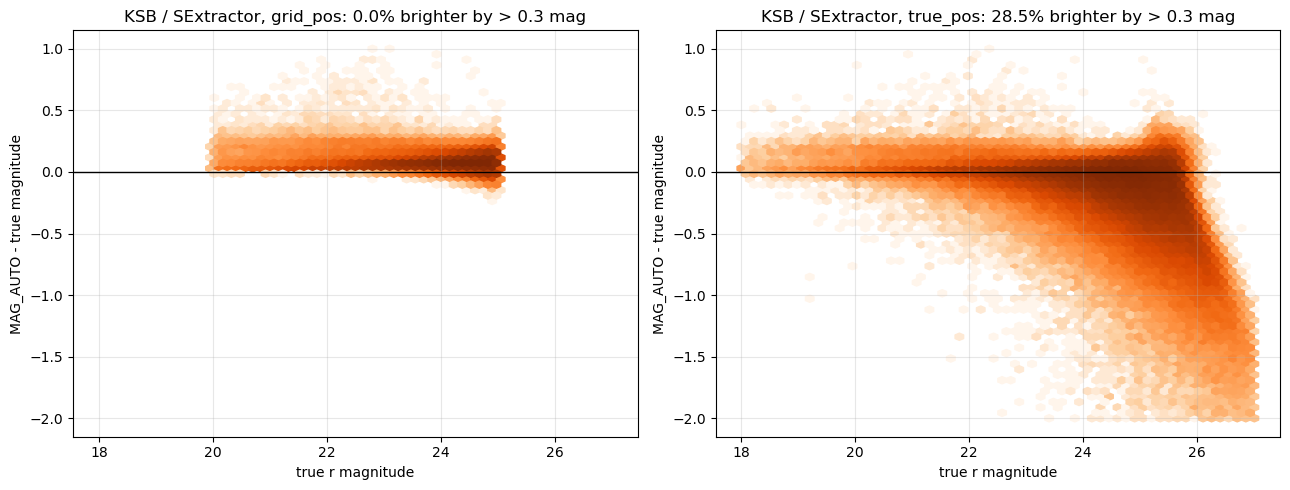

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, setup in zip(axes, ['grid_pos', 'true_pos']):
    d = load(setup, 'ksb', 'p000p000', 0)
    d = d[(d.id_input >= 0) & (d.star == 0) & d.valid & (d.snr > 10)]
    ax.hexbin(d.mag_true, d.mag_obs - d.mag_true, gridsize=60, bins='log', cmap='Oranges',
              extent=(18, 27, -2, 1), mincnt=1)
    ax.axhline(0, c='k', lw=1)
    ax.set_xlabel('true r magnitude'); ax.set_ylabel('MAG_AUTO - true magnitude')
    ax.set_title(f'KSB / SExtractor, {setup}: {(d.mag_obs - d.mag_true < -0.3).mean():.1%} brighter by > 0.3 mag')
plt.tight_layout(); plt.show()

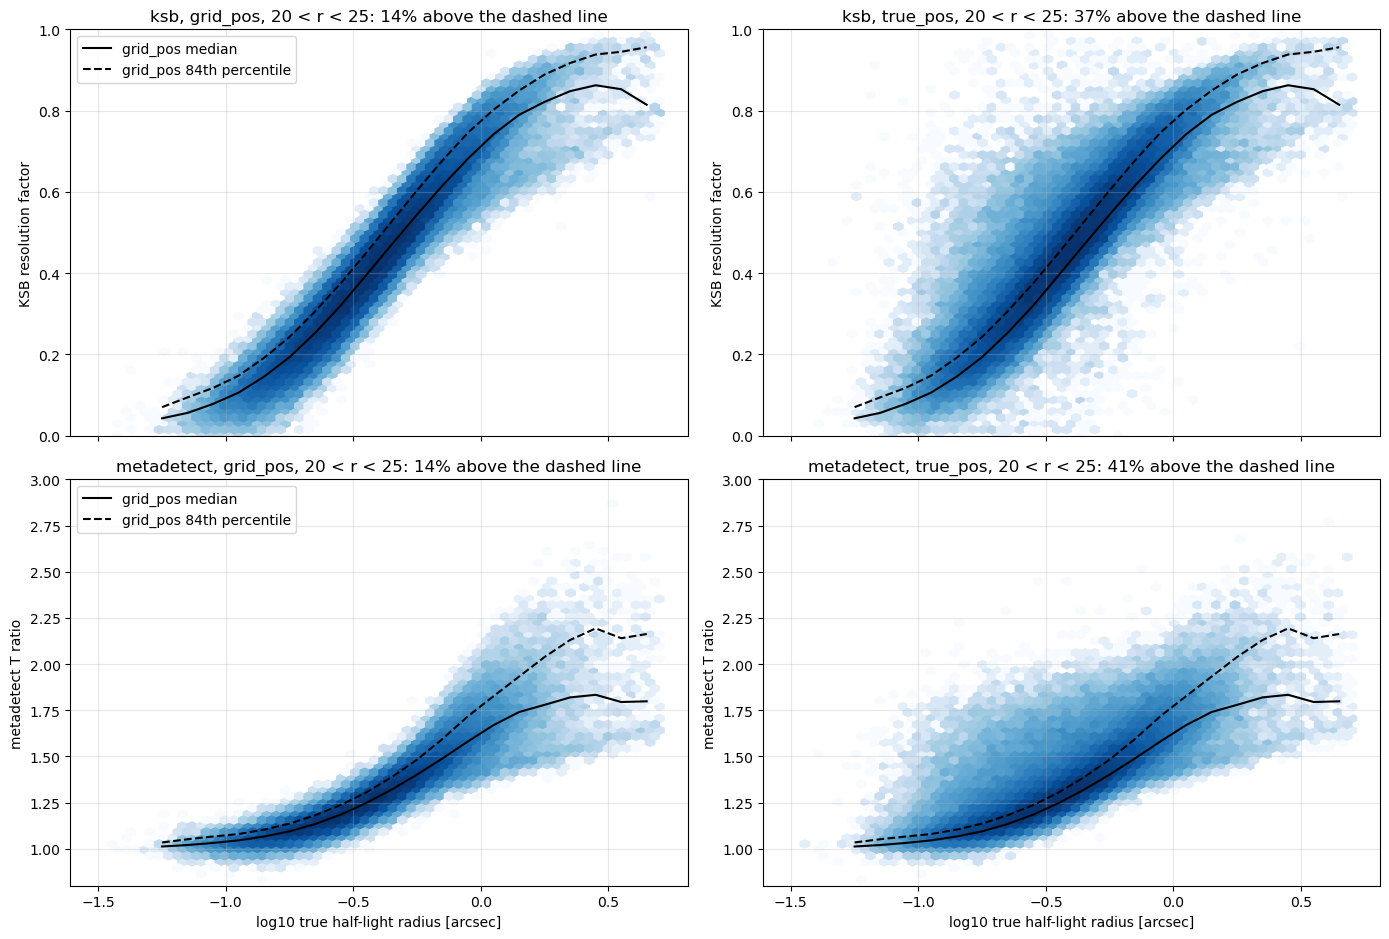

In [11]:
def matched_galaxies(setup, method):
    # matched, valid galaxies with S/N > 10 and 20 < r_true < 25 (the grid's range), in the g = 0, rot0 run
    d = load(setup, method, 'p000p000', 0)
    m = (d.id_input >= 0) & (d.star == 0) & d.valid & (d.snr > 10) & (d.mag_true > 20) & (d.mag_true < 25)
    if method == 'metadetect':
        m &= d.shear_type == 'noshear'
    return d[m]


lbins = np.linspace(-1.5, 0.7, 23)                       # log10 true half-light radius
mid = 0.5 * (lbins[1:] + lbins[:-1])
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5), sharex=True)
for row, method, label, ylim in zip(axes, METHODS, ['KSB resolution factor', 'metadetect T ratio'], [(0, 1), (0.8, 3)]):
    ## the grid's median and 84th percentile of size_obs, per bin of true size
    grid = matched_galaxies('grid_pos', method)
    k = np.digitize(np.log10(grid.size_true.values), lbins) - 1
    q50, q84 = (np.array([np.percentile(grid.size_obs.values[k == i], q) if (k == i).sum() > 30 else np.nan
                          for i in range(len(mid))]) for q in (50, 84))
    ok = np.isfinite(q84)
    for ax, setup in zip(row, ['grid_pos', 'true_pos']):
        d = grid if setup == 'grid_pos' else matched_galaxies(setup, method)
        x = np.log10(d.size_true.values)
        ax.hexbin(x, d.size_obs, gridsize=60, bins='log', cmap='Blues', mincnt=1, extent=(-1.5, 0.7, *ylim))
        ax.plot(mid, q50, 'k-', lw=1.5, label='grid_pos median')
        ax.plot(mid, q84, 'k--', lw=1.5, label='grid_pos 84th percentile')
        above = (d.size_obs.values > np.interp(x, mid[ok], q84[ok])).mean()
        ax.set_ylim(ylim); ax.set_ylabel(label)
        ax.set_title(f'{method}, {setup}, 20 < r < 25: {above:.0%} above the dashed line')
    row[0].legend(loc='upper left')
for ax in axes[1]:
    ax.set_xlabel('log10 true half-light radius [arcsec]')
plt.tight_layout(); plt.show()

### Questions

1. Down to which magnitude is the sample complete?
2. What fraction of SExtractor detections in `true_pos` are noticeably brighter than the galaxy they are matched to? What causes this?

## Shear catalogues: a first look

The metadetect catalogue has one row per object **per shear type**, so select `shear_type == 'noshear'` to look at the objects themselves. Only valid measurements are shown.

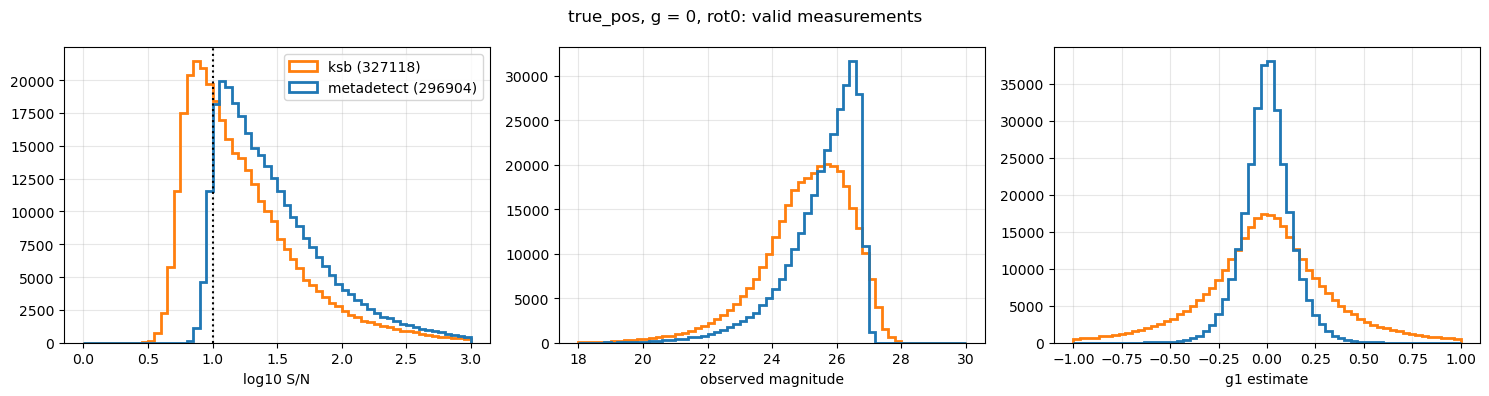

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for method in METHODS:
    d = load('true_pos', method, 'p000p000', 0)
    if method == 'metadetect':
        d = d[d.shear_type == 'noshear']
    d = d[d.valid]
    kw = dict(histtype='step', lw=2, color=COLORS[method], label=f'{method} ({len(d)})')
    axes[0].hist(np.log10(d.snr[d.snr > 0]), bins=60, range=(0, 3), **kw)
    axes[1].hist(d.mag_obs, bins=60, range=(18, 30), **kw)
    axes[2].hist(d.g1, bins=60, range=(-1, 1), **kw)
axes[0].set_xlabel('log10 S/N'); axes[1].set_xlabel('observed magnitude'); axes[2].set_xlabel('g1 estimate')
axes[0].axvline(1, c='k', ls=':'); axes[0].legend()
plt.suptitle('true_pos, g = 0, rot0: valid measurements'); plt.tight_layout(); plt.show()

The two S/N are different quantities, so the same threshold keeps different galaxies. KSB's is SExtractor's `FLUX_AUTO / FLUXERR_AUTO`: the flux in an elliptical (Kron) aperture, where every pixel counts equally, and so does its noise. Metadetect's `wmom_s2n` is the S/N of a flux weighted by a fixed Gaussian, which gives the noisy outer pixels little weight. For the same galaxies in `true_pos`, it is about 1.7 times KSB's at r < 25, and 1.4 times at 26 < r < 27. This has nothing to do with the calibration: the response $R$ rescales the shear, not the S/N.

## The shear-bias machinery

You don't need to change the next cell, but read the docstrings. Everything else in the notebook calls `shear_bias()`.

- **`cut(d)`** is any function that returns a boolean mask on a catalogue, for example `lambda d: d.snr > 10`. It is applied **to every catalogue separately**: each shear run, each rotation, and for metadetect each of `noshear`, `1p` and `1m`. This is what lets metadetect see, and correct, how the selection responds to shear.
- **`ids`** (optional) restricts the sample to a fixed list of input objects.
- **$m_1$ and $c_1$** come from a least-squares straight line through the three shear runs, the mean estimated $\hat g_1$ against the input $g_1$.
- **Errors** come from a jackknife over NJK × NJK patches on the sky. The patches are the same for every shear and rotation, so the noise cancellation carries into the errors.

In [13]:
@functools.lru_cache(maxsize=4)
def patch_edges(setup):
    d = load(setup, 'ksb', 'p000p000', 0)
    q = np.linspace(0, 1, NJK + 1)
    return np.quantile(d.x, q), np.quantile(d.y, q)


def _sums(setup, method, tag, rot, cut=None, ids=None):
    # per-patch [sum w g1, sum w, count] for one catalogue; for metadetect, rows noshear, 1p, 1m
    d = load(setup, method, tag, rot)
    xe, ye = patch_edges(setup)
    p = (np.clip(np.digitize(d.x.values, xe) - 1, 0, NJK - 1) * NJK
         + np.clip(np.digitize(d.y.values, ye) - 1, 0, NJK - 1))
    mask = d.valid.values.copy()
    if cut is not None:
        mask &= np.asarray(cut(d), dtype=bool)
    if ids is not None:
        mask &= np.isin(d.id_input.values, ids[rot])
    types = [None] if method == 'ksb' else ['noshear', '1p', '1m']
    out = np.zeros((len(types), 3, NJK**2))
    wg, w = (d.w * d.g1).values, d.w.values
    for i, t in enumerate(types):
        m = mask if t is None else mask & (d.shear_type.values == t)
        out[i, 0] = np.bincount(p[m], weights=wg[m], minlength=NJK**2)
        out[i, 1] = np.bincount(p[m], weights=w[m], minlength=NJK**2)
        out[i, 2] = np.bincount(p[m], minlength=NJK**2)
    return out


def _g_hat(S, method):
    # shear estimate and response from patch-summed sums S[type, (sum wg, sum w, n)]
    with np.errstate(divide='ignore', invalid='ignore'):    # empty bins give NaN
        mean = S[:, 0] / S[:, 1]
    if method == 'ksb':
        return mean[0], 1.0
    R = (mean[1] - mean[2]) / (2 * STEP)
    with np.errstate(divide='ignore', invalid='ignore'):
        return mean[0] / R, R


def shear_bias(setup, method, cut=None, ids=None):
    '''
    m1, c1 (and the metadetect response R11) of a sample, with jackknife errors.
    m1 and c1 come from a least-squares straight line <g1_hat> = (1 + m1) g1_true + c1 through the three shear runs;
    R11 is the response in the unsheared run.

    setup  : one of SETUPS
    method : 'ksb' or 'metadetect'
    cut    : function catalogue -> boolean mask, applied to every catalogue separately
    ids    : {rot: array of id_input}, to fix the sample to these input objects
    returns: dict with m1, c1, R11, their errors, the number of objects at g = 0 (per rotation)
             and the jackknife samples (*_jk), for errors on differences
    '''
    parts = {tag: sum(_sums(setup, method, tag, rot, cut, ids) for rot in ROTS) for tag in SHEARS}
    g_true = np.array(list(SHEARS.values()))
    x = g_true - g_true.mean()

    def est(P):
        g_hat = np.array([_g_hat(P[tag], method)[0] for tag in SHEARS])
        slope = (x * g_hat).sum() / (x**2).sum()           # least squares; NaN propagates for empty samples
        c1 = g_hat.mean() - slope * g_true.mean()
        return np.array([slope - 1, c1, _g_hat(P['p000p000'], method)[1]])

    full = est({t: v.sum(-1) for t, v in parts.items()})
    jk = np.array([est({t: v.sum(-1) - v[..., i] for t, v in parts.items()}) for i in range(NJK**2)])
    err = np.sqrt((NJK**2 - 1) / NJK**2 * ((jk - jk.mean(0))**2).sum(0))
    return dict(m1=full[0], m1_err=err[0], c1=full[1], c1_err=err[1], R11=full[2], R11_err=err[2],
                N=parts['p000p000'][0, 2].sum() / len(ROTS), m1_jk=jk[:, 0], c1_jk=jk[:, 1], R11_jk=jk[:, 2])


def jk_err(a_jk, b_jk):
    # jackknife error of a difference of two estimates from the same patches
    d = a_jk - b_jk
    return np.sqrt((len(d) - 1) / len(d) * ((d - d.mean())**2).sum())


def fmt(r):
    return f"m1 = {r['m1']:+.4f} ± {r['m1_err']:.4f},  c1 = {r['c1']:+.5f} ± {r['c1_err']:.5f}"

## 3. The mean shear bias of the whole sample

We start with our **fiducial selection**: valid measurements with S/N > 10, plus, for metadetect, `size_obs > 0.5` on the T ratio. The T ratio is measured on the PSF-convolved image, where a point source has a T ratio of 1, so this is a loose cut: it removes only outliers and keeps the stars. Exercise 3 comes back to the stars, with a tighter size cut.

In [14]:
FIDUCIAL = FIDUCIAL_CUT      # defined in the first code cell

rows = []
for setup in SETUPS:
    for method in METHODS:
        r = shear_bias(setup, method, cut=FIDUCIAL[method])
        rows.append(dict(setup=setup, method=method, N=int(r['N']), m1=r['m1'], m1_err=r['m1_err'],
                         c1=r['c1'], c1_err=r['c1_err'], R11=r['R11'] if method == 'metadetect' else np.nan))
table1 = pd.DataFrame(rows)
table1.round({'m1': 4, 'm1_err': 4, 'c1': 5, 'c1_err': 5, 'R11': 3})

,setup,method,N,m1,m1_err,c1,c1_err,R11
0,grid_pos,ksb,126879,-0.0219,0.0066,-0.00009,0.00013,NaN
1,grid_pos,metadetect,132248,0.0099,0.0093,0.00020,0.00019,0.284
2,random_pos,ksb,207216,-0.2368,0.0076,-0.00057,0.00026,NaN
3,random_pos,metadetect,283562,0.0096,0.0291,0.00008,0.00087,0.196
4,true_pos,ksb,206533,-0.2435,0.0076,-0.00012,0.00031,NaN
5,true_pos,metadetect,279347,-0.0331,0.0230,-0.00073,0.00077,0.197
6,true_pos_stars,ksb,208700,-0.2875,0.0085,-0.00012,0.00031,NaN
7,true_pos_stars,metadetect,291063,-0.0573,0.0240,-0.00085,0.00077,0.187


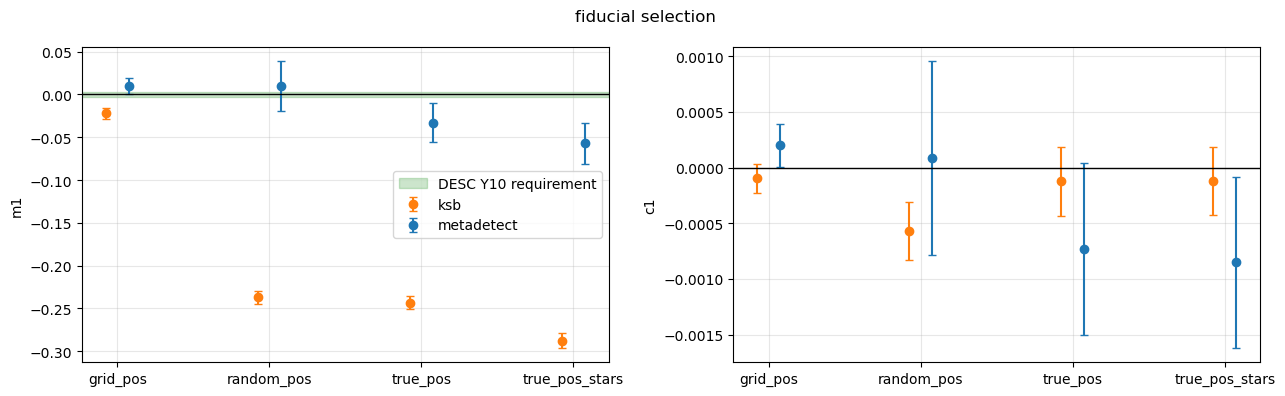

In [15]:
def plot_bias_per_setup(table, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    x = np.arange(len(SETUPS))
    for k, method in enumerate(METHODS):
        t = table[table.method == method].set_index('setup').loc[SETUPS]
        for ax, q in zip(axes, ['m1', 'c1']):
            ax.errorbar(x + (k - 0.5) * 0.15, t[q], t[q + '_err'], fmt='o', capsize=3,
                        color=COLORS[method], label=method)
    for ax, q in zip(axes, ['m1', 'c1']):
        ax.axhline(0, c='k', lw=1); ax.set_xticks(x); ax.set_xticklabels(SETUPS); ax.set_ylabel(q)
    axes[0].axhspan(-3e-3, 3e-3, color='g', alpha=0.2, label='DESC Y10 requirement')
    axes[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.show()


plot_bias_per_setup(table1, 'fiducial selection')

### Questions

1. How does KSB's $m_1$ change from `grid_pos` to `random_pos`? Then from `random_pos` to `true_pos` and `true_pos_stars`? Which change matters most: blending, clustering, or stars?

## 4. Shear bias as a function of galaxy properties

Cosmic-shear analyses split galaxies into bins of redshift, which in practice means bins of photometric redshift and magnitude, and the bias is needed *per bin*. We bin by:
- **observed** quantities (`mag_obs`, `size_obs`). These can be measured in real data. For metadetect, binning by an observed quantity is just another selection, which the 1p/1m catalogues calibrate.
- **true** quantities (`mag_true`, `size_true`, `z_true`). These are only known in simulations, and only for detections matched to the input. Unmatched objects drop out, and metadetect's response can't calibrate a selection on the truth: what does that imply?

In [16]:
def bias_in_bins(setup, method, col, bins, cut=None):
    rows = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        c = lambda d, lo=lo, hi=hi: (d[col] >= lo) & (d[col] < hi) & (cut(d) if cut else True)
        r = shear_bias(setup, method, cut=c)
        rows.append(dict(lo=lo, hi=hi, mid=0.5 * (lo + hi), N=r['N'], m1=r['m1'], m1_err=r['m1_err'], R11=r['R11']))
    return pd.DataFrame(rows)


def plot_bins(col, bins, setups=('random_pos', 'true_pos'), xlabel=None, vline=None):
    # vline: optional (x, label) of a vertical reference line
    fig, axes = plt.subplots(1, len(setups), figsize=(6.5 * len(setups), 4), sharey=True, squeeze=False)
    for ax, setup in zip(axes[0], setups):
        for k, method in enumerate(METHODS):
            t = bias_in_bins(setup, method, col, bins, cut=FIDUCIAL[method])
            ok = t.N > 100
            ax.errorbar(t.mid[ok] + (k - 0.5) * 0.1 * np.diff(bins).min(), t.m1[ok], t.m1_err[ok],
                        fmt='o-', capsize=3, color=COLORS[method], label=method)
        if vline is not None:
            ax.axvline(vline[0], c='k', ls=':', label=vline[1])
        ax.axhline(0, c='k', lw=1); ax.set_xlabel(xlabel or col); ax.set_title(setup)
    axes[0, 0].set_ylabel('m1'); axes[0, 0].legend(); plt.tight_layout(); plt.show()

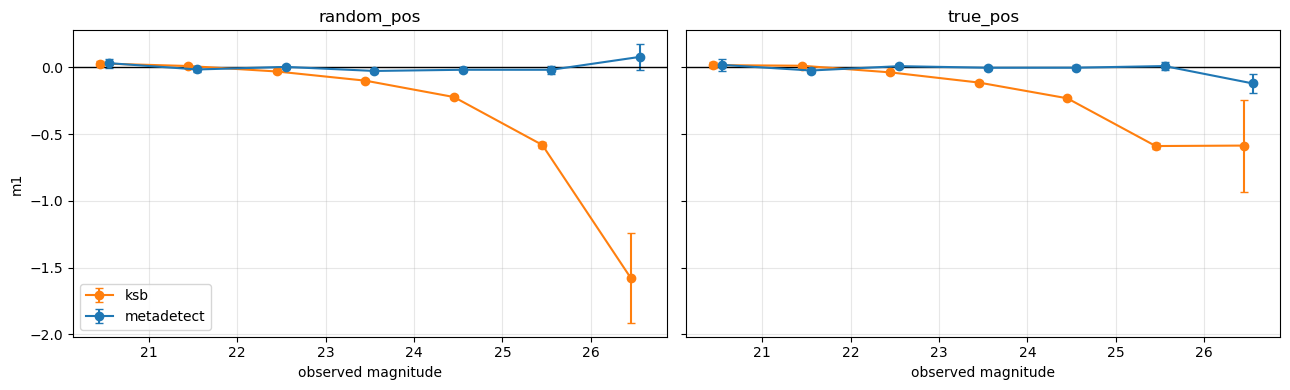

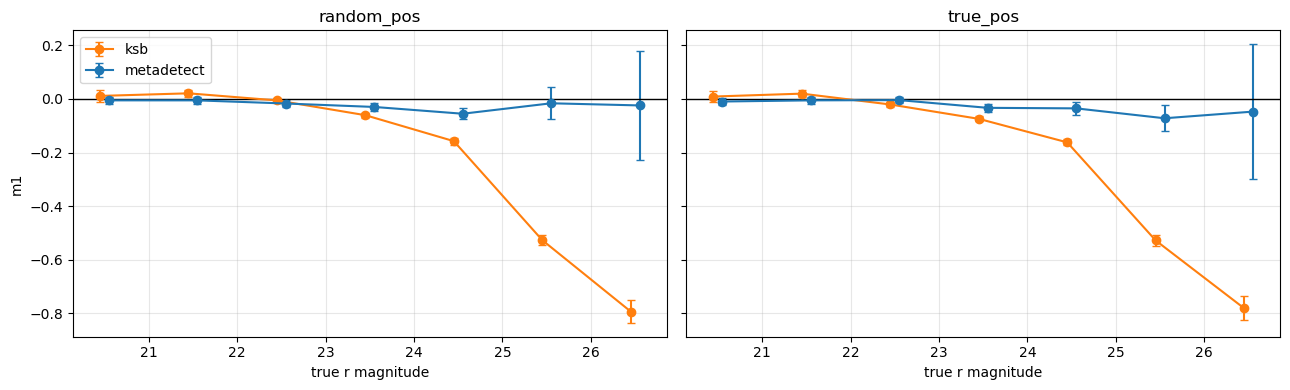

In [17]:
mag_bins = np.arange(20, 27.5, 1.0)
plot_bins('mag_obs', mag_bins, xlabel='observed magnitude')
plot_bins('mag_true', mag_bins, xlabel='true r magnitude')

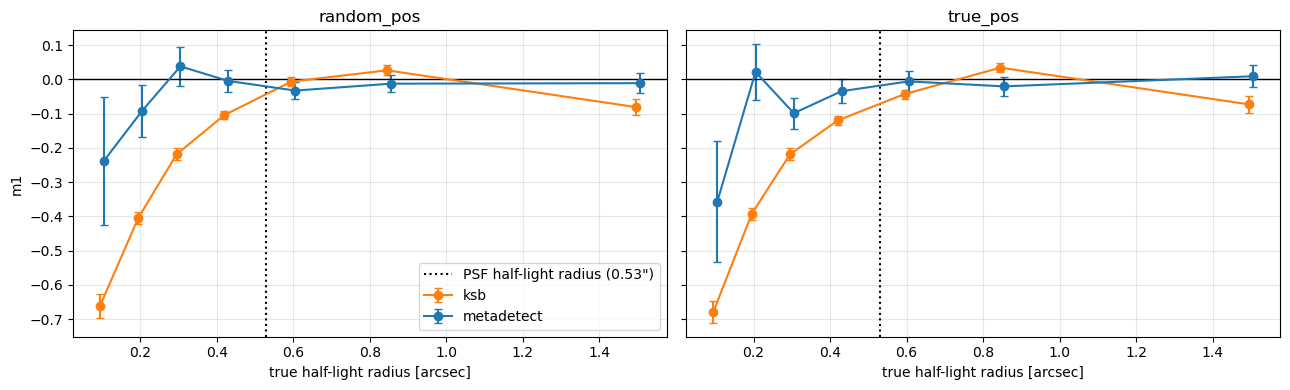

In [18]:
plot_bins('size_true', np.array([0.05, 0.15, 0.25, 0.35, 0.5, 0.7, 1.0, 2.0]), xlabel='true half-light radius [arcsec]',
          vline=(PSF_HLR, f'PSF half-light radius ({PSF_HLR}")'))

`size_obs` means a different thing for each method: KSB's resolution factor, metadetect's $T$ ratio. So each method is binned on its own scale, in bins holding equal numbers of objects (quantiles of the g = 0 sample):

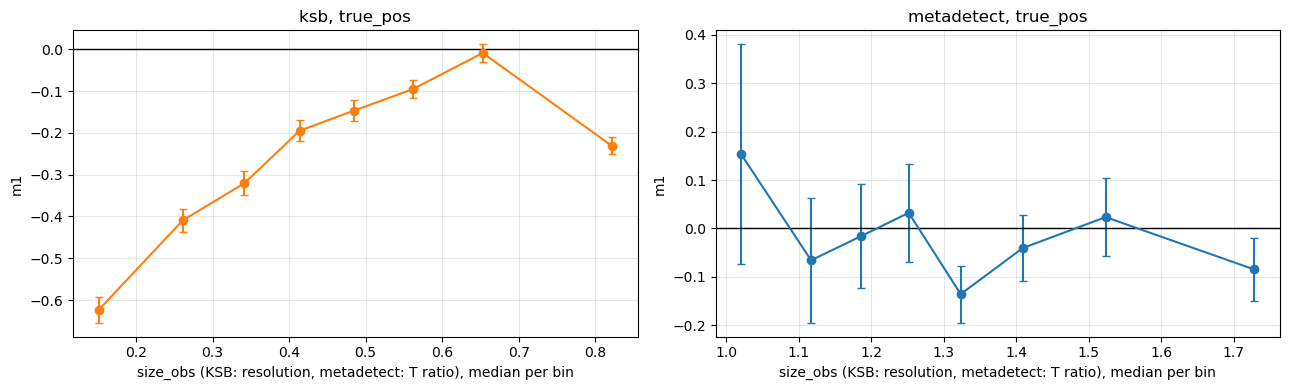

In [19]:
def plot_bins_quantile(setup, col, nbins=8, xlabel=None):
    fig, axes = plt.subplots(1, len(METHODS), figsize=(6.5 * len(METHODS), 4))
    for ax, method in zip(axes, METHODS):
        d = load(setup, method, 'p000p000', 0)
        ref = d.valid & FIDUCIAL[method](d)
        if method == 'metadetect':
            ref &= d.shear_type == 'noshear'
        vals = d[col][ref].values
        bins = np.unique(np.nanquantile(vals, np.linspace(0, 1, nbins + 1)))
        bins[-1] = np.nextafter(bins[-1], np.inf)    # keep the largest value
        t = bias_in_bins(setup, method, col, bins, cut=FIDUCIAL[method])
        med = [np.nanmedian(vals[(vals >= lo) & (vals < hi)]) for lo, hi in zip(bins[:-1], bins[1:])]
        ax.errorbar(med, t.m1, t.m1_err, fmt='o-', capsize=3, color=COLORS[method])
        ax.axhline(0, c='k', lw=1); ax.set_xlabel(f'{xlabel or col}, median per bin'); ax.set_ylabel('m1')
        ax.set_title(f'{method}, {setup}')
    plt.tight_layout(); plt.show()


plot_bins_quantile('true_pos', 'size_obs', xlabel='size_obs (KSB: resolution, metadetect: T ratio)')

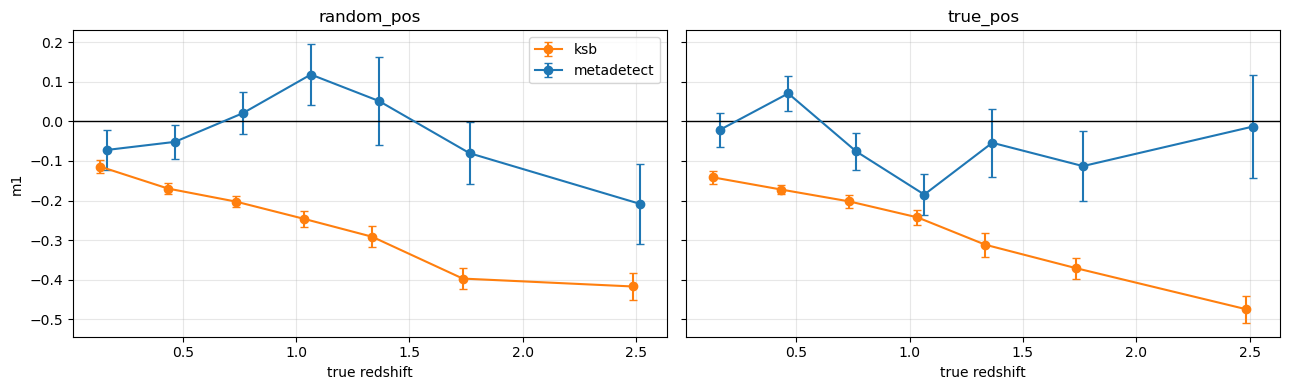

In [20]:
plot_bins('z_true', np.array([0.0, 0.3, 0.6, 0.9, 1.2, 1.5, 2.0, 3.0]), xlabel='true redshift')

### Questions

1. Is the bias as a function of *true* redshift what a cosmic-shear analysis needs? Is that what you can actually calibrate in practice?
2. For metadetect, compare $m_1$ binned by `mag_obs` with $m_1$ binned by `mag_true`. Which is calibrated, and why?

## 5. Where does the bias come from? Measurement, selection and detection

The total shear bias of a catalogue has three sources:

- **Measurement bias:** for a *fixed* set of objects, the measured shapes don't respond to shear exactly as they should. Causes include noise bias, model bias, PSF residuals, and light from blended neighbours.
- **Selection bias:** the cuts (S/N, size, …) are made on quantities that themselves change with the shear. So the selected sample differs between shears.
- **Detection bias:** *which objects are detected*, and how blends are split or merged, depends on the shear.

Metadetection corrects all three, because it detects, selects and measures the objects anew in each artificially sheared image: its response $R$ includes them all. We split $R$ with the definitions of metacalibration (Sheldon & Huff 2017), anchored on the `noshear` catalogue:

| part | how it is measured | corrects |
|---|---|---|
| shape response $R_\gamma$ | objects selected in `noshear`, measured in `1p` and `1m`: $\langle g_{\rm 1p} - g_{\rm 1m}\rangle / 2\Delta\gamma$ | measurement bias |
| selection response $R_S$ | the same objects with their `noshear` shapes, selected once by their `1p` and once by their `1m` measurements: $(\langle g\rangle_{S_{\rm 1p}} - \langle g\rangle_{S_{\rm 1m}}) / 2\Delta\gamma$ | selection bias |
| detection response $R_D$ | the rest, $R - R_\gamma - R_S$: what detecting anew in every sheared image adds | detection bias |

The `1p` and `1m` measurements of a `noshear` object come from the object at the same position in those catalogues. The catalogues give every position with the artificial shear removed: neighbouring objects show no relative stretch between the catalogues. So the same object has the same position in all three, up to centroid noise of a few hundredths of an arcsecond, and we pair them within 0.2″. No input truth is used.

A shear estimate divides the mean shape by a calibration response, $\hat g = \langle g\rangle / R_{\rm cal}$. The mean shape responds to a shear $\gamma$ with the whole response, $\langle g\rangle \approx (R_\gamma + R_S + R_D)\,\gamma$, so $m = (R_\gamma + R_S + R_D)/R_{\rm cal} - 1$. Metadetection calibrates with all of it, $R_{\rm cal} = R$, and has $m \approx 0$. A method that calibrated only the shapes, $R_{\rm cal} = R_\gamma$, would be left with

$$m = m_{\rm sel} + m_{\rm det}, \qquad m_{\rm sel} = \frac{R_S}{R_\gamma}, \qquad m_{\rm det} = \frac{R_D}{R_\gamma}.$$

$m_{\rm sel}$ and $m_{\rm det}$ are the **selection and detection biases** that metadetection removes, multiplicative biases like $m_1$ in Section 3. (The shape response itself is far from 1: the raw `wmom` shapes respond to only about 20–30% of a shear, and $R_\gamma$ calibrates that.)

**What this assumes.** The split takes metadetection's responses at face value: it assumes that the artificial shear changes the shapes, the selection and the detection exactly as a real lensing shear would. In particular, it assumes that the shape response corrects the shapes completely, so that no measurement bias is left once the shapes are divided by $R_\gamma$. Then $m_{\rm sel}$ and $m_{\rm det}$ are the only biases that a shape-only calibration would leave. The split itself cannot test this, because it uses only the `1p` and `1m` images. Only a comparison with the real shear runs can, and Section 3 makes it for the total: metadetection's $m_1$ is consistent with zero within its errors of 0.01–0.03, except in `true_pos_stars`.

In [21]:
from scipy.spatial import cKDTree


def pair_up(A, B, radius=0.2):
    # indices of the objects of A and B that are each other's nearest neighbour within `radius` arcsec
    c = np.cos(np.radians(np.median(A.y)))
    a, b = np.c_[A.x * c, A.y] * 3600, np.c_[B.x * c, B.y] * 3600
    d_ab, i_ab = cKDTree(b).query(a)
    d_ba, i_ba = cKDTree(a).query(b)
    ok = (d_ab < radius) & (i_ba[i_ab] == np.arange(len(A)))
    return np.where(ok)[0], i_ab[ok]


@functools.lru_cache(maxsize=64)
def counterparts(setup, tag, rot, radius):
    # for each valid noshear object of one catalogue, the index of its 1p and of its 1m counterpart (-1: none)
    d = load(setup, 'metadetect', tag, rot)
    d = d[d.valid]
    N, P, M = (d[d.shear_type == t] for t in ['noshear', '1p', '1m'])
    jP, jM = np.full(len(N), -1), np.full(len(N), -1)
    i, k = pair_up(N, P, radius); jP[i] = k
    i, k = pair_up(N, M, radius); jM[i] = k
    return jP, jM


def response_split(setup, cut, radius=0.2):
    """
    metadetect's response R11 split with metacalibration's definitions, from the noshear, 1p and 1m catalogues
    of the three shear runs and both rotations, with jackknife errors over the NJK x NJK patches.
    R_shape: objects selected in noshear, with a counterpart in both 1p and 1m: <g(1p) - g(1m)> / 2 STEP
    R_sel  : the same objects, with their noshear shapes, selected by their 1p and by their 1m measurements
    R      : metadetect's own response, each catalogue detected and selected on its own
    R_det  : the rest, R - R_shape - R_sel
    also returns m_sel = R_sel / R_shape, m_det = R_det / R_shape, the share of the noshear sample that is paired,
    and the jackknife samples of m_det (m_det_jk), for errors on differences
    """
    xe, ye = patch_edges(setup)
    patch = lambda d: (np.clip(np.digitize(d.x.values, xe) - 1, 0, NJK - 1) * NJK
                       + np.clip(np.digitize(d.y.values, ye) - 1, 0, NJK - 1))
    bc = lambda p, w=None: np.bincount(p, weights=w, minlength=NJK**2)
    S = np.zeros((7, NJK**2))       # per patch: shape sum and count, selection sum and count, total sum and count, noshear count
    for tag in SHEARS:
        for rot in ROTS:
            d = load(setup, 'metadetect', tag, rot)
            d = d[d.valid]
            N, P, M = (d[d.shear_type == t] for t in ['noshear', '1p', '1m'])
            sN, sP, sM = (np.asarray(cut(x), dtype=bool) for x in (N, P, M))
            jP, jM = counterparts(setup, tag, rot, radius)          # the 1p and 1m counterpart of each noshear object
            both = (jP >= 0) & (jM >= 0)
            pN, gN = patch(N), N.g1.values
            g = both & sN
            S[0] += bc(pN[g], P.g1.values[jP[g]] - M.g1.values[jM[g]]); S[1] += bc(pN[g])
            byP, byM = both.copy(), both.copy()
            byP[both] = sP[jP[both]]; byM[both] = sM[jM[both]]
            S[2] += bc(pN[byP], gN[byP]) - bc(pN[byM], gN[byM]); S[3] += 0.5 * (bc(pN[byP]) + bc(pN[byM]))
            S[4] += bc(patch(P)[sP], P.g1.values[sP]) - bc(patch(M)[sM], M.g1.values[sM])
            S[5] += 0.5 * (bc(patch(P)[sP]) + bc(patch(M)[sM])); S[6] += bc(pN[sN])

    def est(T):
        shape, sel, R = T[0] / T[1] / (2 * STEP), T[2] / T[3] / (2 * STEP), T[4] / T[5] / (2 * STEP)
        det = R - shape - sel
        return np.array([shape, sel, det, R, sel / shape, det / shape, T[1] / T[6]])

    full = est(S.sum(-1))
    jk = np.array([est(S.sum(-1) - S[:, i]) for i in range(NJK**2)])
    err = np.sqrt((NJK**2 - 1) / NJK**2 * ((jk - jk.mean(0))**2).sum(0))
    names = ['R_shape', 'R_sel', 'R_det', 'R', 'm_sel', 'm_det', 'paired']
    return {**dict(zip(names, full)), **{n + '_err': e for n, e in zip(names, err)}, 'm_det_jk': jk[:, 5]}


split = pd.DataFrame([dict(setup=setup, **response_split(setup, FIDUCIAL['metadetect'])) for setup in SETUPS])
split[['setup', 'R', 'R_shape', 'R_sel', 'R_sel_err', 'm_sel', 'm_sel_err', 'paired']].round(4)

,setup,R,R_shape,R_sel,R_sel_err,m_sel,m_sel_err,paired
0,grid_pos,0.2861,0.2929,-0.0000,0.0000,-0.0001,0.0001,0.9943
1,random_pos,0.1978,0.1972,-0.0033,0.0008,-0.0167,0.0042,0.9732
2,true_pos,0.2024,0.2021,-0.0039,0.0008,-0.0195,0.0042,0.9723
3,true_pos_stars,0.1922,0.1853,-0.0036,0.0008,-0.0197,0.0042,0.9728


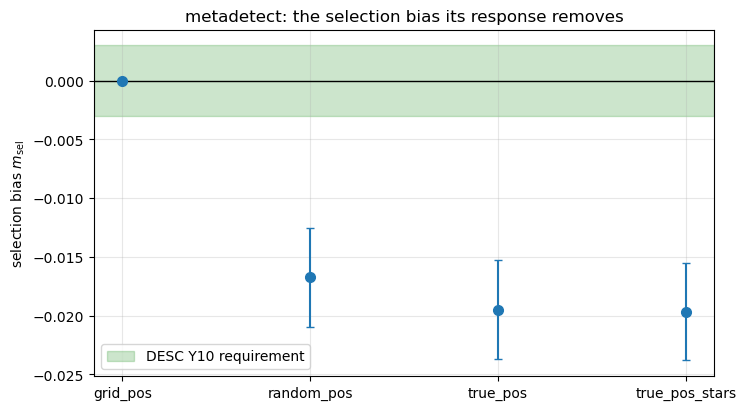

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(SETUPS))
ax.errorbar(x, split.m_sel, split.m_sel_err, fmt='o', capsize=3, ms=7, color='tab:blue')
ax.axhline(0, c='k', lw=1); ax.axhspan(-3e-3, 3e-3, color='g', alpha=0.2, label='DESC Y10 requirement')
ax.set_xticks(x); ax.set_xticklabels(SETUPS); ax.legend()
ax.set_ylabel(r'selection bias $m_{\rm sel}$'); ax.set_title('metadetect: the selection bias its response removes')
plt.show()

### Why the detection bias is hard to measure

The detection part is the rest, $R_D = R - R_\gamma - R_S$. $R$ does not depend on any pairing, but $R_\gamma$ does: it needs *the same object* in `1p` and `1m`, and the catalogues can only find it by position. For most objects that is unambiguous. But a blend can be split differently in the two sheared images, and its pieces then sit at slightly different positions, by 0.1–1″. Is that the same object, re-measured, or a new detection? The pairing radius decides. A small radius counts these objects as detections; a large one counts them in $R_\gamma$, where their apparent change of shape (which really comes from the different deblending) lowers $R_\gamma$ and raises $R_D$.

Below we repeat the split of `true_pos` for pairing radii from 0.1″ to 1″.

Hoekstra, Kannawadi & Kitching (2021, A&A 646, A124) avoid the problem by not measuring shapes for this test at all. They give every detected object the *true* sheared ellipticity of its nearest input galaxy, computed from its intrinsic ellipticity and the applied shear. Each image is matched to its own input catalogue, never across shears. With 90°-rotated pairs, the true shapes of the input galaxies average to exactly zero, so any bias of the mean over the *detected* objects can only come from which objects are detected. Blends still need a choice, though: a detection that overlaps several input galaxies has to be given the shape of one of them. Hoekstra et al. take the nearest input galaxy, or a brighter one within 3 pixels (0.3″).

We cannot follow their approach here for a practical reason. It needs each input galaxy's intrinsic ellipticity, and when we copied the catalogues to the RSP we kept only the axis ratio (`axis_ratio_true`), not the orientation. The simulation inputs contain both, so the test is possible in principle.

,paired,R,R_shape,m_sel,m_det
radius,,,,,
0.1,0.9493,0.2024,0.2043,-0.0183,0.0092
0.2,0.9723,0.2024,0.2021,-0.0195,0.0209
0.5,0.9805,0.2024,0.1941,-0.0215,0.0645
1.0,0.9820,0.2024,0.1921,-0.0216,0.0755


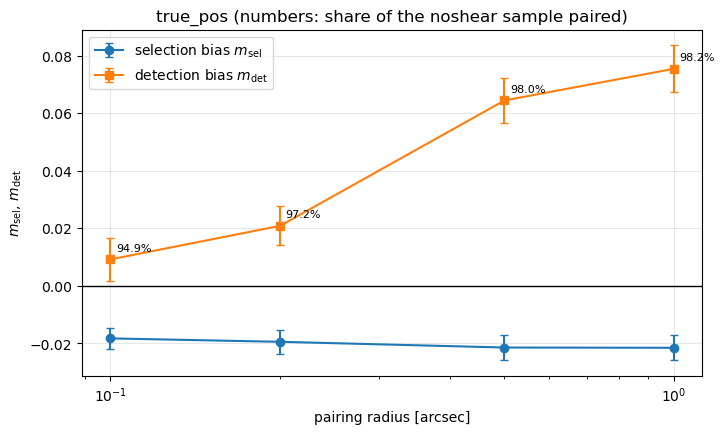

In [23]:
radii = [0.1, 0.2, 0.5, 1.0]
res = [response_split('true_pos', FIDUCIAL['metadetect'], r) for r in radii]
display(pd.DataFrame([{k: r[k] for k in ['paired', 'R', 'R_shape', 'm_sel', 'm_det']} for r in res], index=pd.Index(radii, name='radius')).round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(radii, [r['m_sel'] for r in res], [r['m_sel_err'] for r in res], fmt='o-', capsize=3, label=r'selection bias $m_{\rm sel}$')
ax.errorbar(radii, [r['m_det'] for r in res], [r['m_det_err'] for r in res], fmt='s-', capsize=3, label=r'detection bias $m_{\rm det}$')
for r, res_r in zip(radii, res):
    ax.annotate(f"{res_r['paired']:.1%}", (r, res_r['m_det']), textcoords='offset points', xytext=(4, 6), fontsize=8)
ax.axhline(0, c='k', lw=1); ax.set_xscale('log'); ax.set_xlabel('pairing radius [arcsec]'); ax.set_ylabel(r'$m_{\rm sel}$, $m_{\rm det}$')
ax.set_title('true_pos (numbers: share of the noshear sample paired)'); ax.legend()
plt.show()

**What the scan shows.**
- The **selection** bias does not depend on the pairing: −0.018 to −0.022 for every radius.
- The **detection** part does: from +0.009 at 0.1″ to +0.076 at 1″, while the share of paired objects grows only from 94.9% to 98.2%. Those few percent of objects carry it. Counting them in $R_\gamma$ lowers it from 0.204 to 0.192, so their apparent change of shape between `1p` and `1m` is far from that of the other objects: they are blends whose pieces moved. So the detection bias is positive here, but its size is uncertain by several percent, depending on where we draw the line between "the same object, re-measured" and "a new detection".

None of this limits metadetection: its $R$ includes the detection response, however we split it. What a catalogue alone cannot do is attribute that response cleanly to detection.

### Questions

1. A method that corrected the shapes but not the selection would be left with the selection bias $m_{\rm sel}$. How large is it in `true_pos`, compared with the DESC requirement of $3\times10^{-3}$?
2. Why does the detection part depend on the pairing radius, while $R$ and the selection part do not?

## 6. Going further

These exercises need some code. Each one builds on the sections named in its title, and uses the functions defined there.

**Exercise 1. The shear sample** (Sections 2 and 3)
1. The densities of Section 2 are raw counts of galaxies with S/N > 10. Forecasts quote an *effective* density, which down-weights galaxies with noisy shapes. Chang et al. (2013, MNRAS 434, 2121) define $n_{\rm eff} = \frac{1}{\Omega}\sum_i \sigma_{\rm SN}^2 / (\sigma_{\rm SN}^2 + \sigma_{m,i}^2)$, with $\sigma_{\rm SN} = 0.26$ and $\sigma_{m,i}$ the measurement error of galaxy $i$, and found $n_{\rm eff} \approx 37$ arcmin⁻² for LSST's ten-year r+i data before blending and masking. Compute $n_{\rm eff}$ for the KSB sample: its weights are $w = 1/(\sigma_e^2 + \sigma_m^2)$, with $\sigma_e = 0.27$. Then apply the resolution cut of the SDSS shape catalogue, $R_2 > 1/3$ (Mandelbaum et al. 2005; `size_obs > 1/3`). How do the raw and the effective densities compare with Chang et al.'s?
2. In `grid_pos`, KSB's completeness falls for the smallest galaxies, while metadetect's stays close to 1. For each bin of true size, count the `grid_pos` galaxies that KSB detects, measures with a valid shape, and keeps with S/N > 10. Which step loses the small galaxies, and why?
3. The grid only contains 20 < r < 25 galaxies, so the comparison of Section 3 with the other setups is not like for like. Rerun its table with an extra cut on the observed magnitude, `20 < mag_obs < 25`, for all setups. Does the jump from grid to random positions remain?

**Exercise 2. Cuts and the response** (Sections 3 and 5)
1. For metadetect in `true_pos`, compute $m_1$ and the response `R11` (`shear_bias(...)['R11']`) for S/N thresholds from 5 to 50. How does `R11` change with the cut, and why does $m_1$ stay close to zero all the same?
2. In 2.1, metadetect's $m_1$ sits below zero at almost every threshold. Is that significant? The samples are nested, so the points share most of their objects and their errors are correlated. Use `jk_err()` on the `m1_jk` of two thresholds to get the error on their difference.
3. Try cuts of your own: on an observed quantity such as `mag_obs`, on the truth such as `mag_true`, or a weird one like `d.g1 > -0.5`. Which cuts does metadetect correct for, and which does it not?

**Exercise 3. Stars** (Section 3)
1. In `true_pos_stars`, some detections are stars, and our fiducial cuts keep them. A star is exactly as large as the PSF, so its metadetect T ratio is about 1. Apply a size cut that removes most of them, `size_obs > 1.2`: what fraction of the sample is still stars (the truth flag `star`)? Even with this cut, metadetect's $m_1$ in `true_pos_stars` stays below `true_pos`. Use `shear_bias()` and `jk_err()` to check whether the gap is significant.
2. The gap could come from the galaxies next to stars. Test it: remove the objects near stars from the cut, and compare `true_pos_stars` with `true_pos` again. Does a mask around the bright stars or around the faint ones matter more? (The detected stars are the rows with `star == 1`; `scipy.spatial.cKDTree` finds each object's distance to the nearest star.)

**Exercise 4. The response split** (Section 5)
1. Repeat the split of `true_pos` with a harsher S/N cut (S/N > 20) and a looser one (S/N > 7). How does the selection bias change, and why?
2. Repeat the split in the bins of observed magnitude of Section 4. In which magnitude range is the selection bias largest, and why?
3. Find the objects behind the radius dependence: those paired within 1″ but not within 0.2″. Compare their S/N, size, distance to the nearest neighbour and apparent shape response with those of the other objects. What are they?

**Exercise 5. Errors and estimators** (Section 3)
1. **Noise cancellation:** use `ROTS = [0]` only and look at how the errors grow; that shows what the rotated twins buy. Then estimate what sharing the noise between the shear runs buys: compare the jackknife error of $\langle\hat g_1\rangle_+ - \langle\hat g_1\rangle_-$ with the error it would have if the two runs were independent.
2. **Weights:** KSB uses inverse-variance weights. What happens with `w = 1`? You can set `load(...)['w'] = 1.0`, then rerun. Remember the loader is cached.
3. **Your own estimator:** the catalogues hold `g2` too. Measure $c_2$ with it; it should be zero here.
4. **More area:** the errors on metadetect's $m$ are a few $10^{-2}$ per setup. How many such tiles would LSST-level calibration need?